# GeoLife 1.3 - EDA

Goal: decide whether *common places* carry any signal under **user-level DP** with ~182 users
(how many distinct users visit each coarse H3 cell?). User ids are replaced by seeded pseudonyms
(`geolife.inside.data.pseudonyms`); real ids never appear below.

If `geolife/inside/data/Geolife Trajectories 1.3/` is missing, the notebook falls back to a small
**synthetic fixture** and prints a banner - numbers are then NOT GeoLife numbers.

In [1]:
import sys, time, math, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline
warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "geolife").exists())
sys.path.insert(0, str(ROOT / "src"))
from geolife.inside import data as gd
from geolife.transfer.geo import filter_speed
import h3

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold"})
C0, C1, C2 = "#2a6f97", "#c8553d", "#8a8f98"   # primary, highlight, neutral
DATA = ROOT / "geolife" / "inside" / "data" / "Geolife Trajectories 1.3"
import os
REAL = (DATA / "Data").is_dir() and not os.environ.get("GEOLIFE_FIXTURE")
SEED = 20261101
print("REAL GeoLife data:", REAL)

REAL GeoLife data: True


In [2]:
def make_fixture(n_users=12, seed=0):
    """Deterministic synthetic fixture (NOT GeoLife): home/work commuters around Beijing."""
    rng = np.random.default_rng(seed)
    hubs = np.array([[39.99, 116.33], [39.91, 116.40], [39.98, 116.31], [39.90, 116.46]])
    rows = []
    for u in range(n_users):
        home = hubs[u % 4] + rng.normal(0, .01, 2); work = hubs[(u + 1) % 4] + rng.normal(0, .01, 2)
        for day in range(20):
            t0 = 1_200_000_000 + (u * 40 + day) * 86400
            for leg, (a, b, h) in enumerate([(home, work, 8), (work, home, 18)]):
                for k in range(120):  # 10 min trip at 5 s sampling
                    f = k / 119
                    p = a + (b - a) * f + rng.normal(0, 1e-5, 2)
                    rows.append((f"{u:03d}", day, t0 + h * 3600 + k * 5, p[0], p[1]))
                for k in range(0, 3600, 60):  # 1 h dwell
                    p = b + rng.normal(0, 1e-4, 2)
                    rows.append((f"{u:03d}", day, t0 + (h + 1) * 3600 + k, p[0], p[1]))
    return pd.DataFrame(rows, columns=["uid", "traj", "t", "lat", "lon"])

def load_points(root):
    """Fast bulk reader (same format as geolife.inside.data.parse_plt, which is cross-checked below)."""
    frames = []
    for ud in sorted((root / "Data").iterdir()):
        for k, f in enumerate(sorted((ud / "Trajectory").glob("*.plt"))):
            d = pd.read_csv(f, skiprows=6, header=None, usecols=[0, 1, 5, 6], names=["lat", "lon", "d", "tm"],
                            dtype={"lat": "float64", "lon": "float64"})
            d["t"] = ((pd.to_datetime(d["d"] + " " + d["tm"], utc=True) - pd.Timestamp("1970-01-01", tz="UTC")) // pd.Timedelta(seconds=1)) if len(d) else 0
            d["uid"] = ud.name; d["traj"] = k
            frames.append(d[["uid", "traj", "t", "lat", "lon"]])
    return pd.concat(frames, ignore_index=True)

cache = ROOT / "geolife" / "inside" / "data" / "points.parquet"
t0 = time.time()
if REAL:
    if cache.exists(): df = pd.read_parquet(cache)
    else:
        df = load_points(DATA); df.to_parquet(cache)
else:
    print("*" * 70, "\n* SYNTHETIC FIXTURE - not GeoLife. Numbers below are illustrative only. *\n" + "*" * 70)
    df = make_fixture()
names = gd.pseudonyms(sorted(df.uid.unique()), SEED)
df["user"] = df.uid.map(names); df = df.drop(columns="uid")
df["traj"] = df.user + "/" + df.traj.astype(str)
print(f"loaded {len(df):,} points in {time.time()-t0:.0f}s")

loaded 24,876,978 points in 244s


In [3]:
# cross-check the fast reader against geolife.inside.data.load_geolife on one user (REAL only)
if REAL:
    uid0 = sorted(p.name for p in (DATA / "Data").iterdir())[1]
    tr = gd.load_geolife(DATA, seed=SEED, max_users=2)
    u0 = names[uid0]
    n_loader = sum(len(t) for t in tr[u0]); n_fast = int((df.user == u0).sum())
    print("loader points:", n_loader, "fast points:", n_fast, "match:", n_loader == n_fast)
    p = tr[u0][0][0]; q = df[df.traj == u0 + "/0"].iloc[0]
    print("first point equal:", (p.t, round(p.lat, 6)) == (int(q.t), round(q.lat, 6)))

loader points: 108607 fast points: 108607 match: True
first point equal: True


## 1. Scale: users, trajectories, points

users=182  trajectories=18,670  points=24,876,978
         min    10%      50%       90%        max
trajs    1.0    3.0     28.0     215.0     2153.0
points  17.0  719.0  35182.0  393717.0  2156994.0


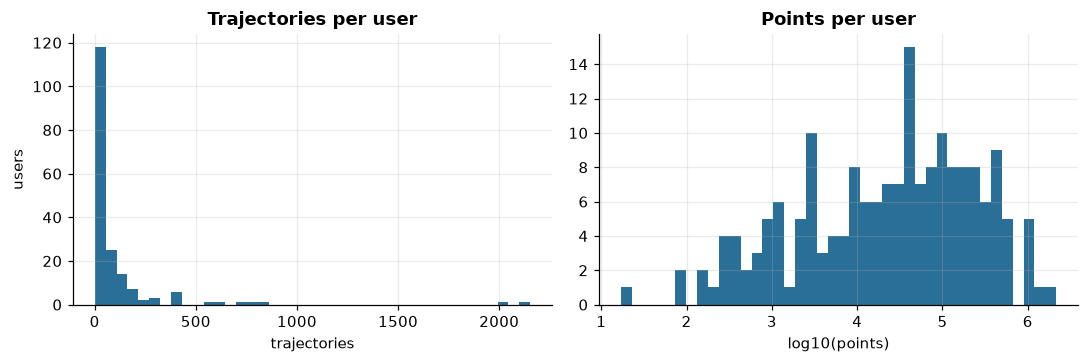

share of points from top 10% of users: 0.562


In [4]:
g = df.groupby("user")
summ = pd.DataFrame({"trajs": g.traj.nunique(), "points": g.size()})
print(f"users={len(summ)}  trajectories={summ.trajs.sum():,}  points={summ.points.sum():,}")
print(summ.describe(percentiles=[.1,.5,.9]).round(0).T[["min","10%","50%","90%","max"]])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(summ.trajs, bins=40, color=C0); ax[0].set(title="Trajectories per user", xlabel="trajectories", ylabel="users")
ax[1].hist(np.log10(summ.points), bins=40, color=C0); ax[1].set(title="Points per user", xlabel="log10(points)")
plt.tight_layout(); plt.show()
top = summ.points.sort_values(ascending=False)
print("share of points from top 10% of users:", round(top.head(max(1, len(top)//10)).sum() / top.sum(), 3))

## 2. Sampling interval, duration, length

sampling dt (s) quantiles 10/50/90/99: [ 1.  2.  5. 19.]


share dt<=5s: 0.965  <=10s: 0.986  >60s: 0.005  dt<=0: 0.0281


implied speed > 70 m/s (outliers): 55060 points (0.00221)


            50%      90%       max
dur_min   42.13   530.41   5807.18
len_km    10.03    48.83   5562.97
n        506.00  3323.10  92645.00


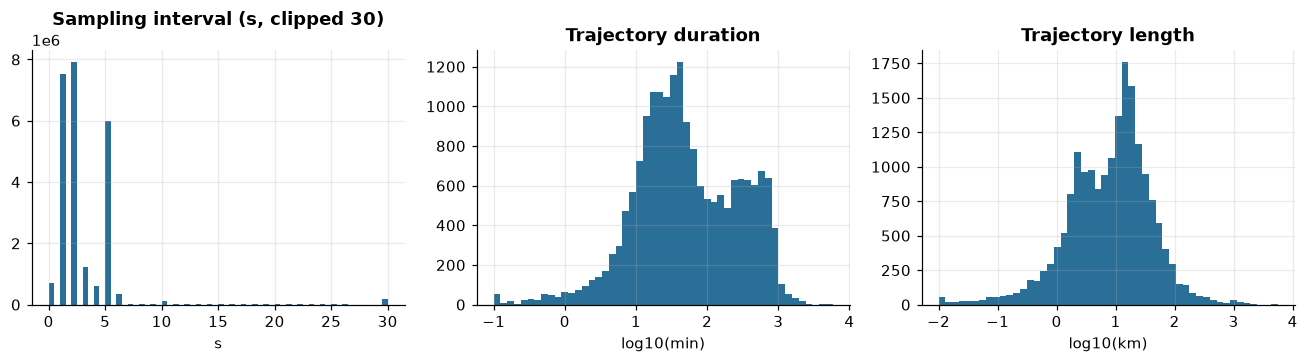

In [5]:
df = df.sort_values(["traj", "t"], kind="stable").reset_index(drop=True)
same = df.traj.values[1:] == df.traj.values[:-1]
dt = np.diff(df.t.values)[same]
lat = np.radians(df.lat.values); lon = np.radians(df.lon.values)
a = np.sin(np.diff(lat)/2)**2 + np.cos(lat[:-1])*np.cos(lat[1:])*np.sin(np.diff(lon)/2)**2
dist = (2*6371008.8*np.arcsin(np.sqrt(np.clip(a, 0, 1))))[same]
print("sampling dt (s) quantiles 10/50/90/99:", np.percentile(dt, [10, 50, 90, 99]))
print("share dt<=5s: %.3f  <=10s: %.3f  >60s: %.3f  dt<=0: %.4f" % ((dt<=5).mean(), (dt<=10).mean(), (dt>60).mean(), (dt<=0).mean()))
with np.errstate(divide="ignore", invalid="ignore"): spd = np.where(dt > 0, dist/dt, np.nan)
print("implied speed > 70 m/s (outliers): %d points (%.5f)" % (np.nansum(spd > 70), np.nanmean(spd > 70)))
ts = df.groupby("traj").agg(t0=("t","min"), t1=("t","max"), n=("t","size"))
ts["dur_min"] = (ts.t1 - ts.t0) / 60
seg_traj = df.traj.values[1:][same]
ln = pd.Series(np.where(dist < 20000, dist, 0)).groupby(seg_traj).sum() / 1000   # ignore >20 km jumps
ts["len_km"] = ln.reindex(ts.index).fillna(0)
print(ts[["dur_min", "len_km", "n"]].describe(percentiles=[.1,.5,.9]).round(2).T[["50%","90%","max"]])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].hist(np.clip(dt, 0, 30), bins=60, color=C0); ax[0].set(title="Sampling interval (s, clipped 30)", xlabel="s")
ax[1].hist(np.log10(ts.dur_min.clip(lower=.1)), bins=50, color=C0); ax[1].set(title="Trajectory duration", xlabel="log10(min)")
ax[2].hist(np.log10(ts.len_km.clip(lower=.01)), bins=50, color=C0); ax[2].set(title="Trajectory length", xlabel="log10(km)")
plt.tight_layout(); plt.show()

## 3. Spatial extent, density, share outside Beijing

points outside Beijing box: 4692705 (18.86%)


users with any point outside Beijing: 101 of 182


invalid coords (|lat|>90 or |lon|>180): 1 | raw lat range 1.04..400.17, lon range -179.97..180.00


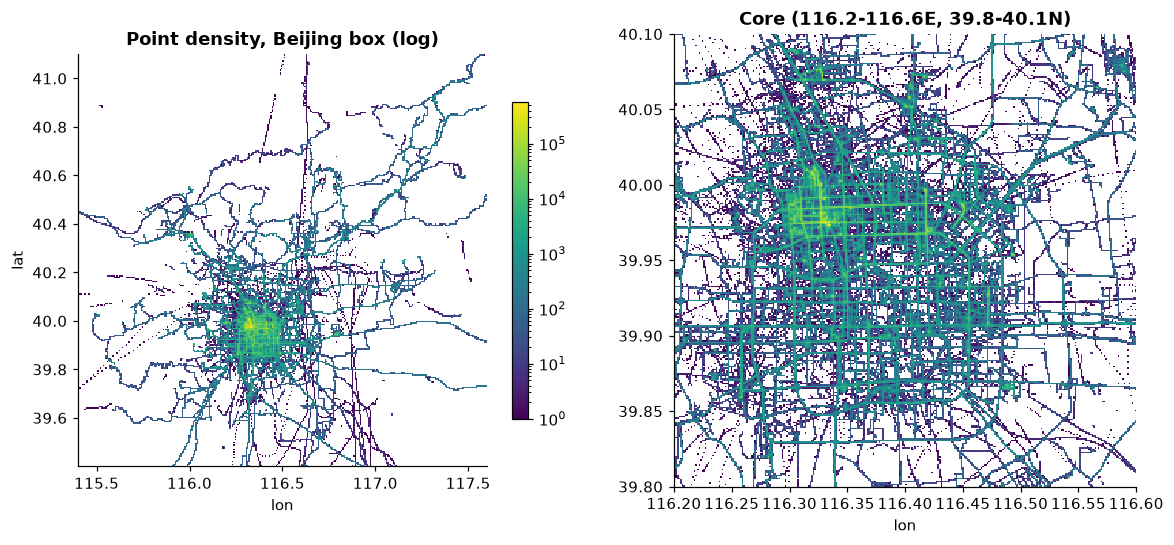

share of in-Beijing points in core box: 0.887


In [6]:
inb = ((df.lat.between(*gd.BEIJING_BBOX[:2])) & (df.lon.between(*gd.BEIJING_BBOX[2:]))).values
print("points outside Beijing box: %d (%.2f%%)" % ((~inb).sum(), 100*(~inb).mean()))
uo = df[~inb].groupby("user").size()
print("users with any point outside Beijing:", len(uo), "of", df.user.nunique())
print("invalid coords (|lat|>90 or |lon|>180):", int(((df.lat.abs()>90)|(df.lon.abs()>180)).sum()), "| raw lat range %.2f..%.2f, lon range %.2f..%.2f" % (df.lat.min(), df.lat.max(), df.lon.min(), df.lon.max()))
d = df[inb]
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
h = ax[0].hist2d(d.lon, d.lat, bins=300, norm=matplotlib.colors.LogNorm(), cmap="viridis")
ax[0].set(title="Point density, Beijing box (log)", xlabel="lon", ylabel="lat", aspect=1/np.cos(np.radians(40)))
ax[0].grid(False); plt.colorbar(h[3], ax=ax[0], shrink=.7)
core = d[d.lon.between(116.2, 116.6) & d.lat.between(39.8, 40.1)]
h = ax[1].hist2d(core.lon, core.lat, bins=300, norm=matplotlib.colors.LogNorm(), cmap="viridis")
ax[1].set(title="Core (116.2-116.6E, 39.8-40.1N)", xlabel="lon", aspect=1/np.cos(np.radians(40))); ax[1].grid(False)
plt.tight_layout(); plt.show()
print("share of in-Beijing points in core box: %.3f" % (len(core)/len(d)))

## 4. Time of day / day of week (Beijing local = UTC+8)

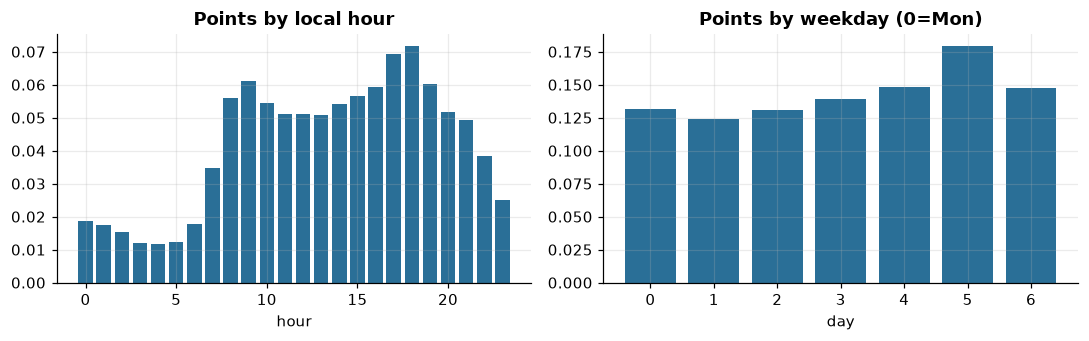

date span: 2000-01-02 07:12:19 -> 2012-07-27 16:31:20


{2000: 0.0, 2007: 0.012, 2008: 0.326, 2009: 0.464, 2010: 0.057, 2011: 0.113, 2012: 0.028}


In [7]:
loc = pd.to_datetime(df.t + 8*3600, unit="s")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(range(24), np.bincount(loc.dt.hour, minlength=24)/len(df), color=C0); ax[0].set(title="Points by local hour", xlabel="hour")
ax[1].bar(range(7), np.bincount(loc.dt.dayofweek, minlength=7)/len(df), color=C0); ax[1].set(title="Points by weekday (0=Mon)", xlabel="day")
plt.tight_layout(); plt.show()
print("date span:", loc.min(), "->", loc.max())
yr = loc.dt.year.value_counts().sort_index(); print((yr/len(df)).round(3).to_dict())

## 5. Labelled transport-mode coverage

users with labels: 69  segments: 14718
            segments   hours  users
mode                               
walk            6460  5460.5     63
bike            2089  2410.3     40
car              993  1725.1     40
bus             2853  1507.0     51
train            299   745.4     20
taxi            1179   659.1     35
subway           813   396.3     27
airplane          17    40.8      6
boat               7     4.6      4
run                6     3.8      6
motorcycle         2     0.2      2


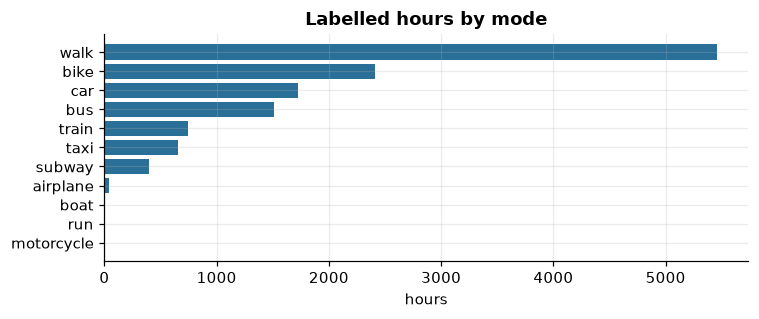

share of points inside a labelled span: 0.218


In [8]:
if REAL:
    rows = []
    for ud in sorted((DATA / "Data").iterdir()):
        lp = ud / "labels.txt"
        if lp.exists():
            for s in gd.read_labels(lp): rows.append((names[ud.name], s.t_start, s.t_end, s.mode))
    lab = pd.DataFrame(rows, columns=["user", "t0", "t1", "mode"]); lab["h"] = (lab.t1 - lab.t0) / 3600
    print("users with labels:", lab.user.nunique(), " segments:", len(lab))
    bm = lab.groupby("mode").agg(segments=("h","size"), hours=("h","sum"), users=("user","nunique")).sort_values("hours", ascending=False)
    print(bm.round(1))
    fig, ax = plt.subplots(figsize=(7, 3)); ax.barh(bm.index[::-1], bm.hours[::-1], color=C0); ax.set(title="Labelled hours by mode", xlabel="hours"); plt.tight_layout(); plt.show()
    # share of all points falling in a labelled span
    cov = 0
    for u, gg in df.groupby("user"):
        l = lab[lab.user == u]
        if len(l):
            idx = np.searchsorted(np.sort(l.t0.values), gg.t.values, side="right") - 1
            t0s, t1s = l.sort_values("t0").t0.values, l.sort_values("t0").t1.values
            ok = idx >= 0; cov += int((gg.t.values[ok] <= t1s[idx[ok]]).sum())
    print("share of points inside a labelled span: %.3f" % (cov/len(df)))
else:
    print("fixture has no labels")

## 6. Stay points (200 m / 20 min rule, points thinned to >=30 s spacing)

16,481 stays from 171 users in 18s
stays/user quantiles 10/50/90/max: [   2.    21.5  253.9 1217. ]
stay duration (h) quantiles 10/50/90: [0.38, 0.78, 3.24]


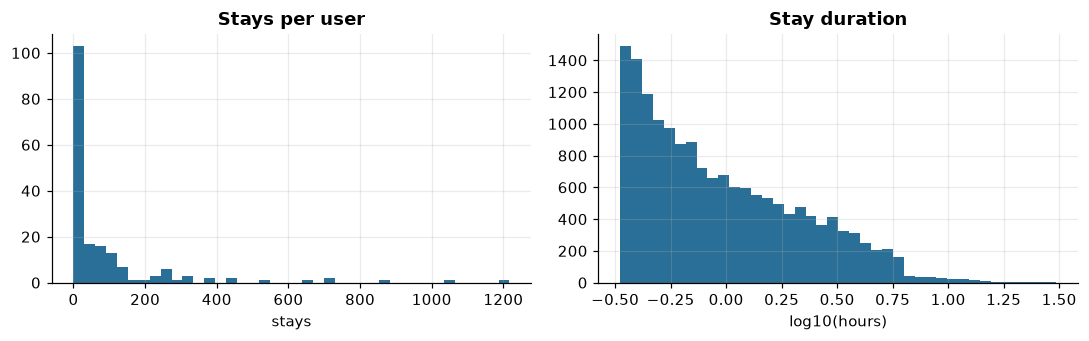

In [9]:
df["thin"] = (df.t // 30)
thin = df.drop_duplicates(["traj", "thin"])
from geolife.transfer.types import GpsPoint
stays = []
t0 = time.time()
for tid, gg in thin.groupby("traj", sort=False):
    pts = [GpsPoint(int(t), la, lo) for t, la, lo in zip(gg.t.values, gg.lat.values, gg.lon.values)]
    for la, lo, a_, b_ in gd.stay_points(filter_speed(pts)):
        stays.append((tid.split("/")[0], la, lo, a_, b_))
st = pd.DataFrame(stays, columns=["user", "lat", "lon", "t0", "t1"]); st["dur_h"] = (st.t1 - st.t0) / 3600
print(f"{len(st):,} stays from {st.user.nunique()} users in {time.time()-t0:.0f}s")
spu = st.groupby("user").size().reindex(summ.index).fillna(0)
print("stays/user quantiles 10/50/90/max:", np.percentile(spu, [10, 50, 90, 100]))
print("stay duration (h) quantiles 10/50/90:", st.dur_h.quantile([.1, .5, .9]).round(2).tolist())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(spu, bins=40, color=C0); ax[0].set(title="Stays per user", xlabel="stays")
ax[1].hist(np.log10(st.dur_h.clip(lower=.3)), bins=40, color=C0); ax[1].set(title="Stay duration", xlabel="log10(hours)")
plt.tight_layout(); plt.show()

## 7. KEY: users per H3 cell - is there cross-user signal for 'common places'?

Under user-level DP each user contributes at most a bounded number of (cell) keys. A cell is only
*estimable* if many distinct users visit it (signal grows with #users, noise does not). We count
distinct users per cell at three resolutions, for (a) all points and (b) stay points only.

In [10]:
def cells_for(frame, res):
    key = frame[["user", "lat", "lon"]].copy()
    key["la"] = key.lat.round(4); key["lo"] = key.lon.round(4)       # ~10 m dedupe before H3
    key = key.drop_duplicates(["user", "la", "lo"])
    key["cell"] = [h3.latlng_to_cell(a, b, res) for a, b in zip(key.la.values, key.lo.values)]
    return key.drop_duplicates(["user", "cell"])[["user", "cell"]]

inB = df[inb]
res_list = [7, 8, 9]
stB = st[st.lat.between(*gd.BEIJING_BBOX[:2]) & st.lon.between(*gd.BEIJING_BBOX[2:])]
out = {}
for res in res_list:
    out[res] = {"pts": cells_for(inB, res), "stay": cells_for(stB, res)}
rows = []
for res in res_list:
    for kind in ("pts", "stay"):
        uc = out[res][kind]; n_u = uc.groupby("cell").user.nunique()
        mass = uc.groupby("user").cell.nunique()
        r = {"res": res, "kind": kind, "cells": len(n_u), "median_users/cell": n_u.median(), "max_users/cell": n_u.max(),
             "median_cells/user": mass.median()}
        for k in (2, 5, 10, 20):
            r[f"cells>={k}u"] = int((n_u >= k).sum())
            # share of (user,cell) incidences that fall in cells with >=k users
            r[f"incid>={k}u"] = round(float(uc.cell.map(n_u).ge(k).mean()), 3)
        rows.append(r)
ov = pd.DataFrame(rows); pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print(ov.to_string(index=False))

 res kind  cells  median_users/cell  max_users/cell  median_cells/user  cells>=2u  incid>=2u  cells>=5u  incid>=5u  cells>=10u  incid>=10u  cells>=20u  incid>=20u
   7  pts   3148                3.0             174               61.0       2082      0.955       1135      0.845         641       0.711         266       0.495
   7 stay    552                1.0             112                8.0        268      0.888        124      0.744          67       0.594          25       0.366
   8  pts  11580                2.0             161              167.0       6867      0.934       3590      0.809        1973       0.664         852       0.456
   8 stay   1236                1.0              71               11.0        600      0.832        195      0.550          63       0.337          21       0.194
   9  pts  38780                2.0             154              486.0      22149      0.920      11124      0.776        5864       0.614        2257       0.388
   9 stay   2575      

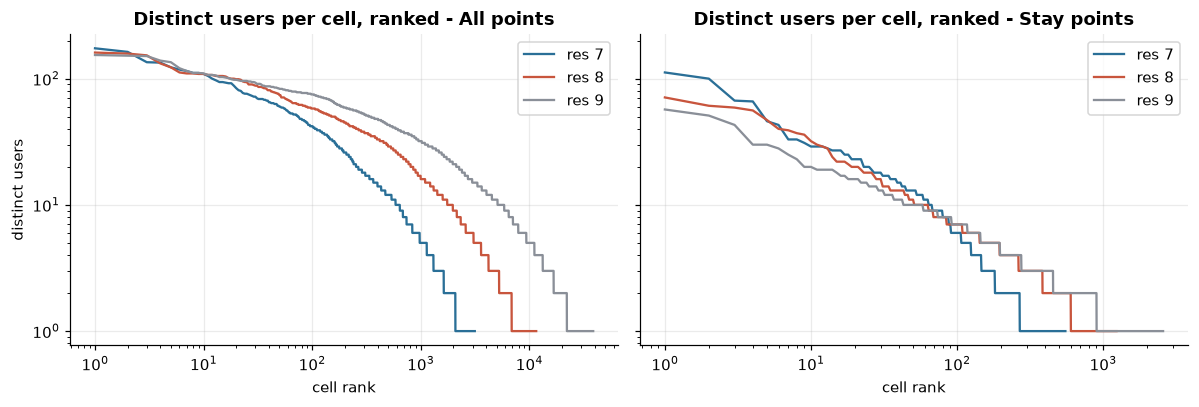

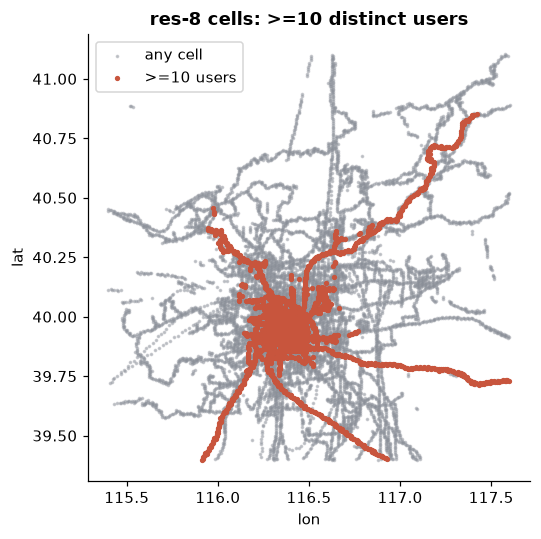

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a_, kind, ttl in zip(ax, ("pts", "stay"), ("All points", "Stay points")):
    for res, col in zip(res_list, (C0, C1, C2)):
        n_u = out[res][kind].groupby("cell").user.nunique().sort_values(ascending=False).values
        a_.loglog(np.arange(1, len(n_u)+1), n_u, color=col, label=f"res {res}")
    a_.set(title=f"Distinct users per cell, ranked - {ttl}", xlabel="cell rank"); a_.legend()
ax[0].set_ylabel("distinct users")
plt.tight_layout(); plt.show()
# Where do multi-user cells sit? res 8 map of cells with >=10 users
n8 = out[8]["pts"].groupby("cell").user.nunique()
big = n8[n8 >= 10]
ll = np.array([h3.cell_to_latlng(c) for c in big.index]) if len(big) else np.zeros((0, 2))
fig, ax = plt.subplots(figsize=(5.5, 5))
allc = np.array([h3.cell_to_latlng(c) for c in n8.index]); ax.scatter(allc[:,1], allc[:,0], s=2, c=C2, alpha=.4, label="any cell")
if len(ll): ax.scatter(ll[:,1], ll[:,0], s=6, c=C1, label=">=10 users")
ax.set(title="res-8 cells: >=10 distinct users", xlabel="lon", ylabel="lat", aspect=1/np.cos(np.radians(40))); ax.legend(); ax.grid(False)
plt.tight_layout(); plt.show()

## Reading the result

See the table in section 7. The decisive columns are `cells>=k u` and `incid>=k u`: the number of
cells (and share of user-cell incidences) that at least k distinct users share. Section
conclusions are summarised in `geolife/inside/reports/eda-summary.md`.